# House Prices: Exploratory Data Analysis and Feature Relationships

**DSAI4204 | Kaggle House Prices – Advanced Regression Techniques**

This notebook examines the supplied `train.csv` and `test.csv`, with an emphasis on:

1. Dataset structure, data types, near-constant fields, and missing values.
2. The distribution of `SalePrice` and `log(SalePrice)`.
3. Numeric features versus price: Pearson, Spearman, and plots.
4. Categorical features versus price: group medians and association strength.
5. Relationships among predictors: correlations and Cramer's V.
6. Potential interactions and nonlinear patterns.
7. Mutual information across all 79 predictors.
8. Train/test consistency, suspicious records, and a combined feature-screening report.

**Important:** This is an *EDA notebook*, not a trained final prediction model. Exploratory rankings are **not** proof that a feature is useful. Any feature selection based on `SalePrice` must be fitted only on training folds during subsequent model-validation experiments.

## 0. Setup and file paths

Place this notebook and `train.csv`, `test.csv`, and `sample_submission.csv` in the same directory. Alternatively, change `DATA_DIR` below. Plots and summary CSVs will be saved in an `eda_outputs` folder.

Dependencies: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`, and `IPython`.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_regression

RANDOM_STATE = 42
TOP_N = 15
SAVE_FIGURES = True

# Change this path if the CSV files are stored elsewhere.
DATA_DIR = Path('.')

# Try a few conventional locations when the default path does not contain the files.
if not (DATA_DIR / 'train.csv').exists():
    candidate_dirs = [Path.cwd() / 'data', Path.cwd().parent / 'data', Path('/mnt/data')]
    DATA_DIR = next((p for p in candidate_dirs if (p / 'train.csv').exists()), DATA_DIR)

required_files = ['train.csv', 'test.csv']
missing_files = [name for name in required_files if not (DATA_DIR / name).exists()]
if missing_files:
    raise FileNotFoundError(
        f'Missing files: {missing_files}. Set DATA_DIR to the folder containing your CSV files.'
    )

OUTPUT_DIR = DATA_DIR / 'eda_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 140)


def finish_plot(file_name):
    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig(OUTPUT_DIR / file_name, dpi=160, bbox_inches='tight')
    plt.show()


print(f'Data directory: {DATA_DIR.resolve()}')
print(f'Output directory: {OUTPUT_DIR.resolve()}')

Data directory: /mnt/data
Output directory: /mnt/data/eda_outputs


## 1. Load the data carefully

The Kaggle data dictionary uses the literal `NA` for many *not-applicable* cases (for example, no garage or no pool). We initially read `NA` as a missing marker so its frequency can be inspected, but we **do not** interpret every missing marker as a data error. The literal string `None` (notably in `MasVnrType`) is preserved as a meaningful category.

`MSSubClass` uses numeric-looking codes for dwelling types and is treated as categorical.

In [2]:
# Preserve the literal category 'None'; interpret only 'NA' and empty cells as missing markers.
read_options = dict(keep_default_na=False, na_values=['NA', ''])
train = pd.read_csv(DATA_DIR / 'train.csv', **read_options)
test = pd.read_csv(DATA_DIR / 'test.csv', **read_options)

train['MSSubClass'] = train['MSSubClass'].astype('string')
test['MSSubClass'] = test['MSSubClass'].astype('string')

assert 'SalePrice' in train.columns and 'SalePrice' not in test.columns
assert train['SalePrice'].notna().all() and (train['SalePrice'] > 0).all()
assert not train['Id'].duplicated().any() and not test['Id'].duplicated().any()

TARGET = 'SalePrice'
IDENTIFIER = 'Id'
FEATURES = [col for col in train.columns if col not in [IDENTIFIER, TARGET]]
assert set(FEATURES) == set(test.columns) - {IDENTIFIER}
assert len(FEATURES) == 79, f'Expected 79 predictors, found {len(FEATURES)}.'

categorical_features = train[FEATURES].select_dtypes(include=['object', 'string', 'category']).columns.tolist()
numeric_features = [col for col in FEATURES if col not in categorical_features]
log_target = np.log(train[TARGET])

print('Train shape:', train.shape)
print('Test shape:', test.shape)
print('Number of predictors:', len(FEATURES))
print('Numeric predictors:', len(numeric_features))
print('Categorical predictors:', len(categorical_features))
print('MSSubClass is categorical:', 'MSSubClass' in categorical_features)
print("MasVnrType entries equal to the literal category 'None':", (train['MasVnrType'] == 'None').sum())
display(train.head(5))

Train shape: (1460, 81)
Test shape: (1459, 80)
Number of predictors: 79
Numeric predictors: 35
Categorical predictors: 44
MSSubClass is categorical: True
MasVnrType entries equal to the literal category 'None': 864


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Group the original 79 data fields

Grouping related fields makes summary tables easier to interpret and can help organize the project report. This grouping is descriptive and does not automatically exclude any feature.

In [3]:
FEATURE_GROUPS = {
    'Land and location': [
        'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley',
        'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope',
        'Neighborhood', 'Condition1', 'Condition2',
    ],
    'Structure and exterior': [
        'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt',
        'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd',
        'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation',
    ],
    'Basement': [
        'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
        'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    ],
    'Interior and living space': [
        'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF',
        '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath',
        'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
        'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu',
    ],
    'Garage and parking': [
        'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars',
        'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive',
    ],
    'Outdoor amenities': [
        'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch',
        'ScreenPorch', 'PoolArea', 'PoolQC', 'Fence', 'MiscFeature', 'MiscVal',
    ],
    'Sale details': ['MoSold', 'YrSold', 'SaleType', 'SaleCondition'],
}

flattened_features = [item for items in FEATURE_GROUPS.values() for item in items]
assert len(flattened_features) == len(set(flattened_features)) == 79
assert set(flattened_features) == set(FEATURES)
feature_to_group = {
    feature: group
    for group, features in FEATURE_GROUPS.items()
    for feature in features
}

group_counts = pd.Series({group: len(fields) for group, fields in FEATURE_GROUPS.items()})
display(group_counts.rename('Feature count').to_frame())

,Feature count
Land and location,14
Structure and exterior,15
Basement,9
Interior and living space,19
Garage and parking,8
Outdoor amenities,10
Sale details,4


## 3. Data quality: missing markers, rare categories, and near-constant fields

**Interpretation warning:** For `PoolQC`, `Alley`, `Fence`, basement-related categories, and garage-related categories, `NA` can mean that the facility does not exist. `LotFrontage` is different: its missing entries generally need a separate imputation decision. Do not drop all high-NA columns without testing their predictive value.

In [4]:
quality_summary = pd.DataFrame({
    'Feature': FEATURES,
    'Group': [feature_to_group[col] for col in FEATURES],
    'Type': ['Categorical' if col in categorical_features else 'Numeric' for col in FEATURES],
    'Train NA count': [int(train[col].isna().sum()) for col in FEATURES],
    'Train NA %': [100.0 * train[col].isna().mean() for col in FEATURES],
    'Test NA count': [int(test[col].isna().sum()) for col in FEATURES],
    'Test NA %': [100.0 * test[col].isna().mean() for col in FEATURES],
    'Unique non-NA values': [int(train[col].nunique(dropna=True)) for col in FEATURES],
    'Most common value share %': [100.0 * train[col].value_counts(dropna=False, normalize=True).iloc[0] for col in FEATURES],
})

quality_summary.sort_values('Train NA %', ascending=False).to_csv(
    OUTPUT_DIR / 'feature_dictionary_and_quality.csv', index=False
)

print('Exact duplicate training rows:', train.duplicated().sum())
print('Training features with at least one NA marker:', (quality_summary['Train NA count'] > 0).sum())
display(quality_summary.sort_values('Train NA %', ascending=False).head(20).round(2))

print('Near-constant or very sparse features (most common value >= 98%):')
display(
    quality_summary.loc[quality_summary['Most common value share %'] >= 98]
    .sort_values('Most common value share %', ascending=False)
    .round(2)
)

Exact duplicate training rows: 0
Training features with at least one NA marker: 19


,Feature,Group,Type,Train NA count,Train NA %,Test NA count,Test NA %,Unique non-NA values,Most common value share %
71,PoolQC,Outdoor amenities,Categorical,1453,99.52,1456,99.79,3,99.52
73,MiscFeature,Outdoor amenities,Categorical,1406,96.30,1408,96.50,4,96.30
5,Alley,Land and location,Categorical,1369,93.77,1352,92.67,2,93.77
72,Fence,Outdoor amenities,Categorical,1179,80.75,1169,80.12,4,80.75
56,FireplaceQu,Interior and living space,Categorical,690,47.26,730,50.03,5,47.26
2,LotFrontage,Land and location,Numeric,259,17.74,227,15.56,110,17.74
58,GarageYrBlt,Garage and parking,Numeric,81,5.55,78,5.35,97,5.55
62,GarageQual,Garage and parking,Categorical,81,5.55,78,5.35,5,89.79
59,GarageFinish,Garage and parking,Categorical,81,5.55,78,5.35,3,41.44
57,GarageType,Garage and parking,Categorical,81,5.55,76,5.21,6,59.59


Near-constant or very sparse features (most common value >= 98%):


,Feature,Group,Type,Train NA count,Train NA %,Test NA count,Test NA %,Unique non-NA values,Most common value share %
8,Utilities,Land and location,Categorical,0,0.00,2,0.14,2,99.93
4,Street,Land and location,Categorical,0,0.00,0,0.00,2,99.59
70,PoolArea,Outdoor amenities,Numeric,0,0.00,0,0.00,8,99.52
71,PoolQC,Outdoor amenities,Categorical,1453,99.52,1456,99.79,3,99.52
13,Condition2,Land and location,Categorical,0,0.00,0,0.00,8,98.97
68,3SsnPorch,Outdoor amenities,Numeric,0,0.00,0,0.00,20,98.36
21,RoofMatl,Structure and exterior,Categorical,0,0.00,0,0.00,8,98.22
44,LowQualFinSF,Interior and living space,Numeric,0,0.00,0,0.00,24,98.22


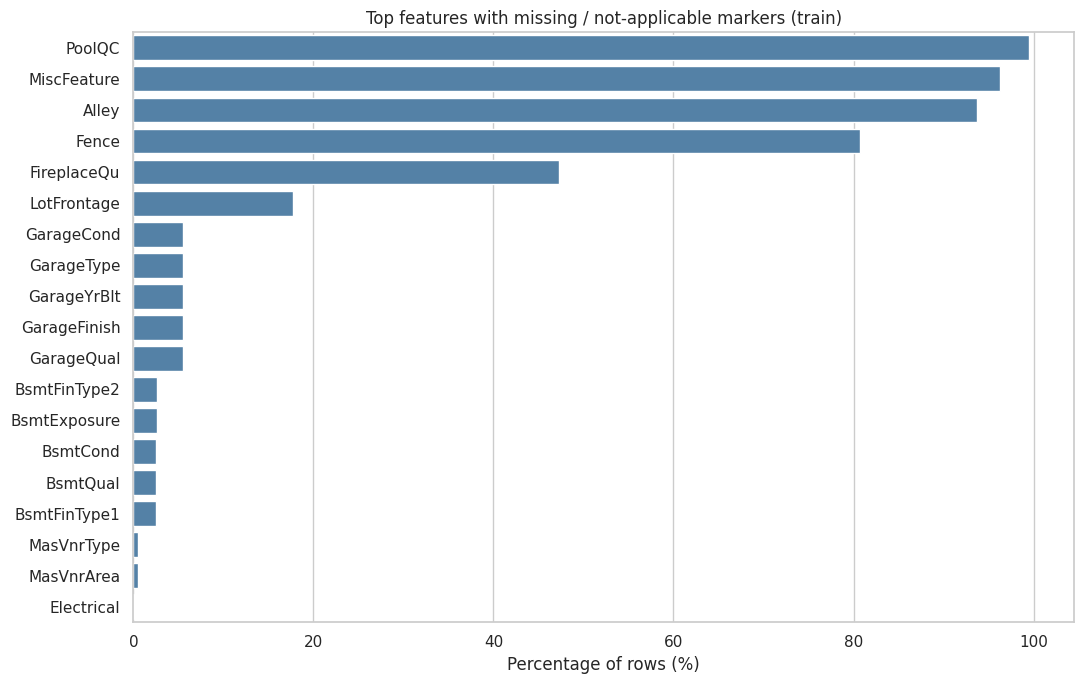

In [5]:
missing_plot = quality_summary.loc[quality_summary['Train NA %'] > 0].copy()
missing_plot = missing_plot.sort_values('Train NA %', ascending=False).head(22)

fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=missing_plot, x='Train NA %', y='Feature', ax=ax, color='steelblue')
ax.set_title('Top features with missing / not-applicable markers (train)')
ax.set_xlabel('Percentage of rows (%)')
ax.set_ylabel('')
finish_plot('01_missing_markers_train.png')

## 4. Target distribution: `SalePrice` and log price

Kaggle evaluates the error on the logarithm of the predicted and observed prices. We examine both `SalePrice` and `log(SalePrice)` to understand the strong right tail before modeling.

SalePrice descriptive statistics:


,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
1%,61815.970000
5%,88000.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
95%,326100.000000


SalePrice skewness: 1.8829
log(SalePrice) skewness: 0.1213


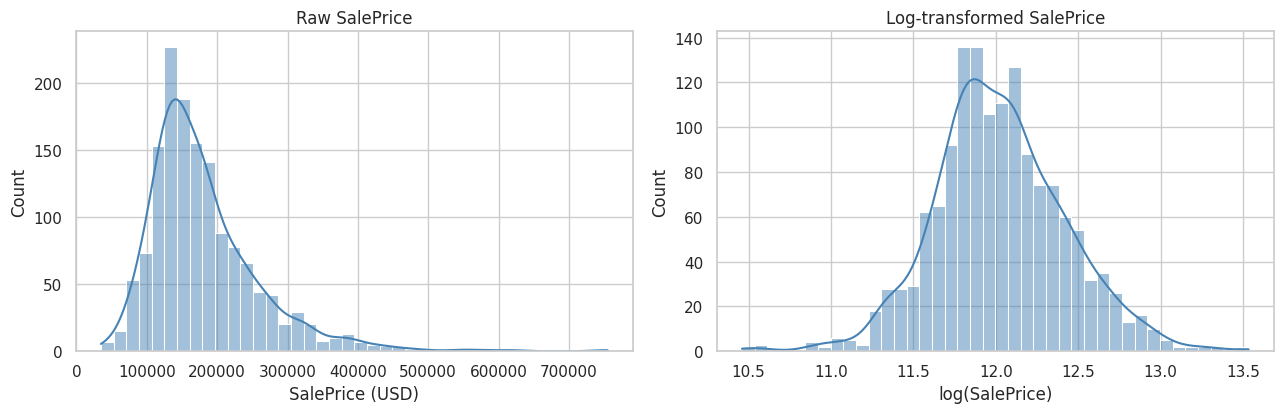

In [6]:
print('SalePrice descriptive statistics:')
display(train['SalePrice'].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).to_frame())
print(f'SalePrice skewness: {train[TARGET].skew():.4f}')
print(f'log(SalePrice) skewness: {log_target.skew():.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
sns.histplot(train[TARGET], bins=40, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Raw SalePrice')
axes[0].set_xlabel('SalePrice (USD)')
sns.histplot(log_target, bins=40, kde=True, ax=axes[1], color='steelblue')
axes[1].set_title('Log-transformed SalePrice')
axes[1].set_xlabel('log(SalePrice)')
finish_plot('02_target_distribution.png')

## 5. Numeric features versus price: Pearson and Spearman

These are **marginal**, one-feature-at-a-time measures. A low correlation does **not** prove that a feature is useless: nonlinear relationships, feature interactions, and redundant predictors can make such rankings misleading.

,Feature,Pearson with log price,Spearman with log price,Abs Pearson,Abs Spearman
2,OverallQual,0.8172,0.8098,0.8172,0.8098
14,GrLivArea,0.7009,0.7313,0.7009,0.7313
24,GarageCars,0.6806,0.6907,0.6806,0.6907
25,GarageArea,0.6509,0.6494,0.6509,0.6494
10,TotalBsmtSF,0.6121,0.6027,0.6121,0.6027
11,1stFlrSF,0.5970,0.5754,0.5970,0.5754
17,FullBath,0.5948,0.6360,0.5948,0.6360
4,YearBuilt,0.5866,0.6527,0.5866,0.6527
5,YearRemodAdd,0.5656,0.5712,0.5656,0.5712
23,GarageYrBlt,0.5411,0.5938,0.5411,0.5938


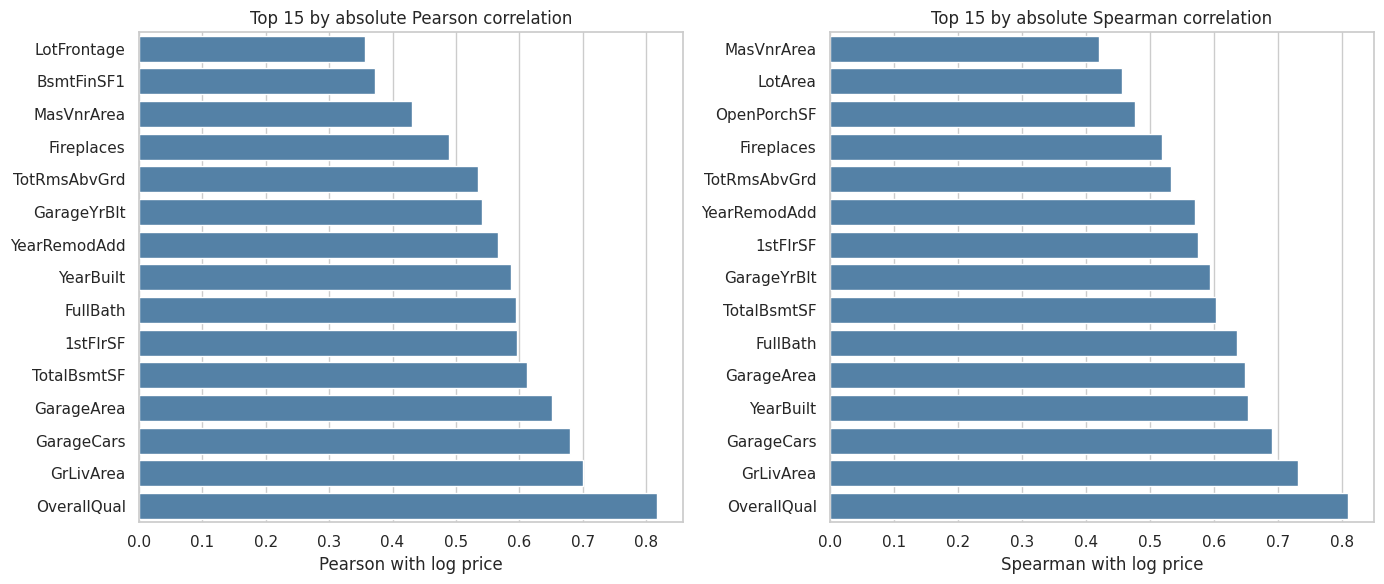

In [7]:
pearson = train[numeric_features].corrwith(log_target, method='pearson')
spearman = train[numeric_features].corrwith(log_target, method='spearman')

numeric_associations = pd.DataFrame({
    'Feature': numeric_features,
    'Pearson with log price': pearson.reindex(numeric_features).values,
    'Spearman with log price': spearman.reindex(numeric_features).values,
})
numeric_associations['Abs Pearson'] = numeric_associations['Pearson with log price'].abs()
numeric_associations['Abs Spearman'] = numeric_associations['Spearman with log price'].abs()
numeric_associations = numeric_associations.sort_values('Abs Pearson', ascending=False)
numeric_associations.to_csv(OUTPUT_DIR / 'numeric_target_associations.csv', index=False)

display(numeric_associations.head(20).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
top_p = numeric_associations.nlargest(TOP_N, 'Abs Pearson').sort_values('Abs Pearson')
top_s = numeric_associations.nlargest(TOP_N, 'Abs Spearman').sort_values('Abs Spearman')
sns.barplot(data=top_p, x='Pearson with log price', y='Feature', ax=axes[0], color='steelblue')
sns.barplot(data=top_s, x='Spearman with log price', y='Feature', ax=axes[1], color='steelblue')
axes[0].set_title(f'Top {TOP_N} by absolute Pearson correlation')
axes[1].set_title(f'Top {TOP_N} by absolute Spearman correlation')
for ax in axes:
    ax.set_ylabel('')
finish_plot('03_numeric_target_correlations.png')

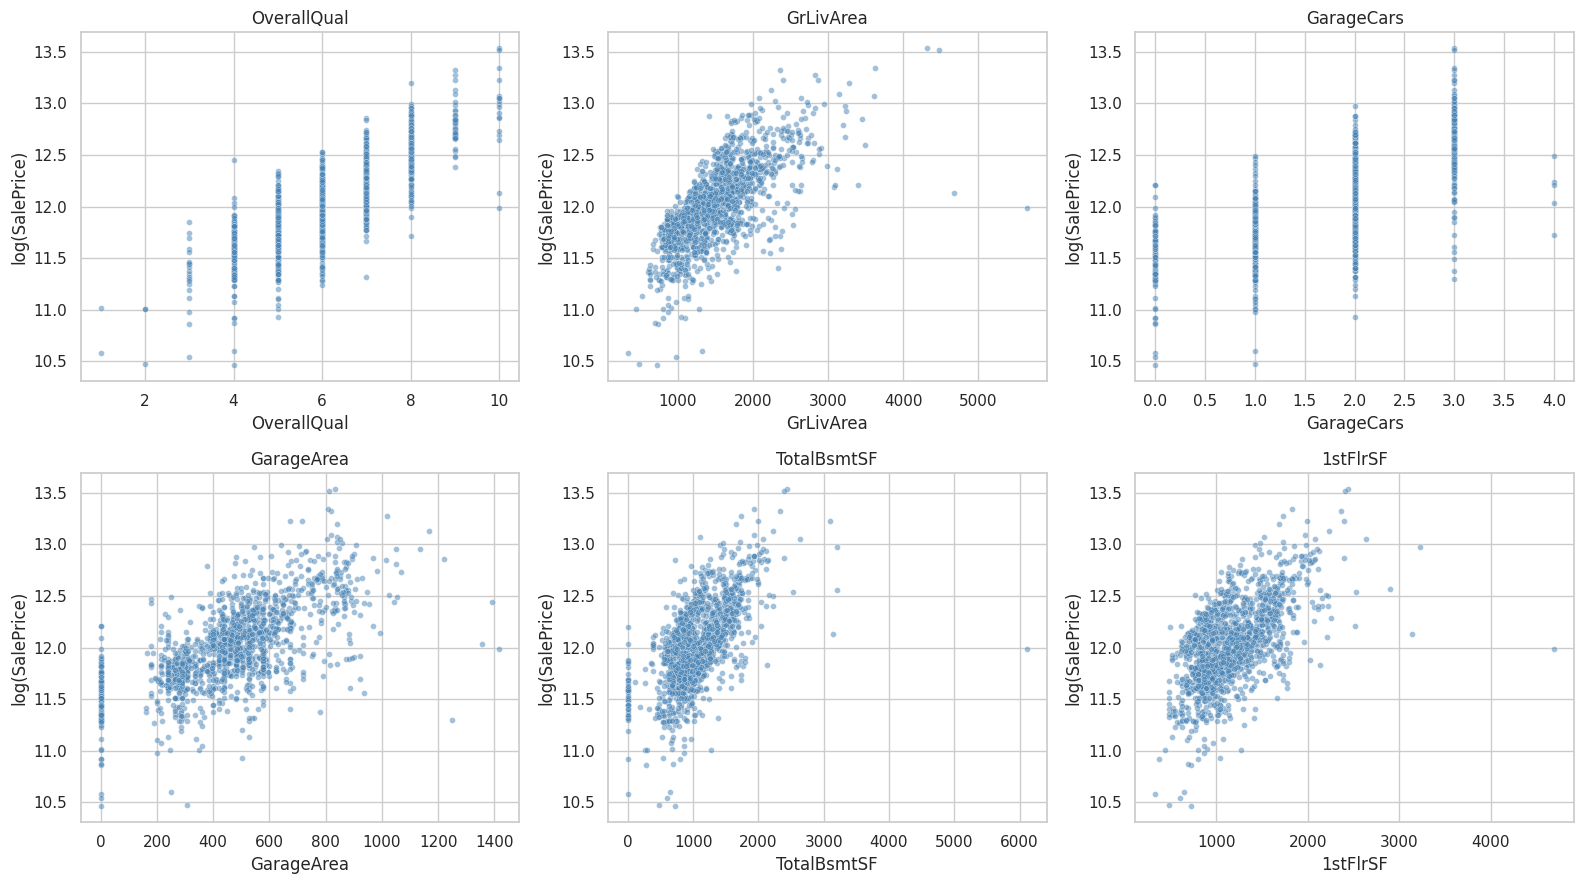

In [8]:
# Scatterplots reveal nonlinear trends, dispersion, and unusual records.
scatter_features = numeric_associations.head(6)['Feature'].tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flat, scatter_features):
    sns.scatterplot(x=train[col], y=log_target, s=18, alpha=0.50, ax=ax, color='steelblue')
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel('log(SalePrice)')

finish_plot('04_top_numeric_scatterplots.png')

## 6. Categorical features versus price

For each category, calculate its sample size and median sale price. We also compute descriptive **eta-squared** (the fraction of variation in `log(SalePrice)` explained by group means). Eta-squared is **not** an out-of-sample predictive score and can favor variables with many categories; small groups should be interpreted cautiously.

,Feature,Eta squared (log price),Category count
9,Neighborhood,0.5708,25
19,ExterQual,0.4611,4
22,BsmtQual,0.4523,5
31,KitchenQual,0.4476,4
35,GarageFinish,0.3810,4
34,GarageType,0.3346,7
0,MSSubClass,0.3301,15
33,FireplaceQu,0.3109,6
21,Foundation,0.3037,6
28,HeatingQC,0.2335,5


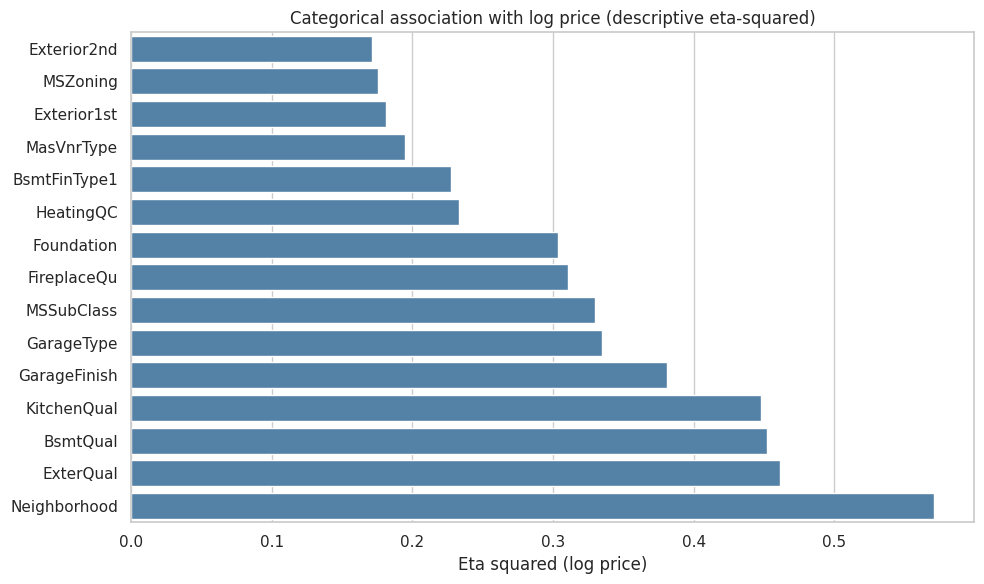

In [9]:
def categorical_eta_squared(category_series, target_series):
    groups = category_series.fillna('__MISSING__').astype(str)
    y = target_series.astype(float)
    overall_mean = y.mean()
    means = y.groupby(groups).mean()
    counts = y.groupby(groups).size()
    between_ss = (counts * (means - overall_mean) ** 2).sum()
    total_ss = ((y - overall_mean) ** 2).sum()
    return float(between_ss / total_ss) if total_ss > 0 else 0.0


categorical_associations = pd.DataFrame({
    'Feature': categorical_features,
    'Eta squared (log price)': [
        categorical_eta_squared(train[col], log_target) for col in categorical_features
    ],
    'Category count': [train[col].nunique(dropna=False) for col in categorical_features],
})
categorical_associations = categorical_associations.sort_values(
    'Eta squared (log price)', ascending=False
)
categorical_associations.to_csv(OUTPUT_DIR / 'categorical_target_associations.csv', index=False)

display(categorical_associations.head(20).round(4))

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=categorical_associations.head(TOP_N).sort_values('Eta squared (log price)'),
    x='Eta squared (log price)', y='Feature', ax=ax, color='steelblue',
)
ax.set_title('Categorical association with log price (descriptive eta-squared)')
ax.set_ylabel('')
finish_plot('05_categorical_target_eta_squared.png')


Neighborhood:


,Count,Median,Mean
_category,,,
NridgHt,77,315000.0,316270.62
NoRidge,41,301500.0,335295.32
StoneBr,25,278000.0,310499.00
Timber,38,228475.0,242247.45
Somerst,86,225500.0,225379.84
Veenker,11,218000.0,238772.73
Crawfor,51,200624.0,210624.73
ClearCr,28,200250.0,212565.43
CollgCr,150,197200.0,197965.77



KitchenQual:


,Count,Median,Mean
_category,,,
Ex,100,316750.0,328554.67
Gd,586,201400.0,212116.02
TA,735,137000.0,139962.51
Fa,39,115000.0,105565.21



MSZoning:


,Count,Median,Mean
_category,,,
FV,65,205950.0,214014.06
RL,1151,174000.0,191004.99
RH,16,136500.0,131558.38
RM,218,120500.0,126316.83
C (all),10,74700.0,74528.00



HouseStyle:


,Count,Median,Mean
_category,,,
2.5Fin,8,194000.0,220000.00
2Story,445,190000.0,210051.76
SLvl,65,164500.0,166703.38
1Story,726,154750.0,175985.48
SFoyer,37,135960.0,135074.49
2.5Unf,11,133900.0,157354.55
1.5Fin,154,132000.0,143116.74
1.5Unf,14,111250.0,110150.00


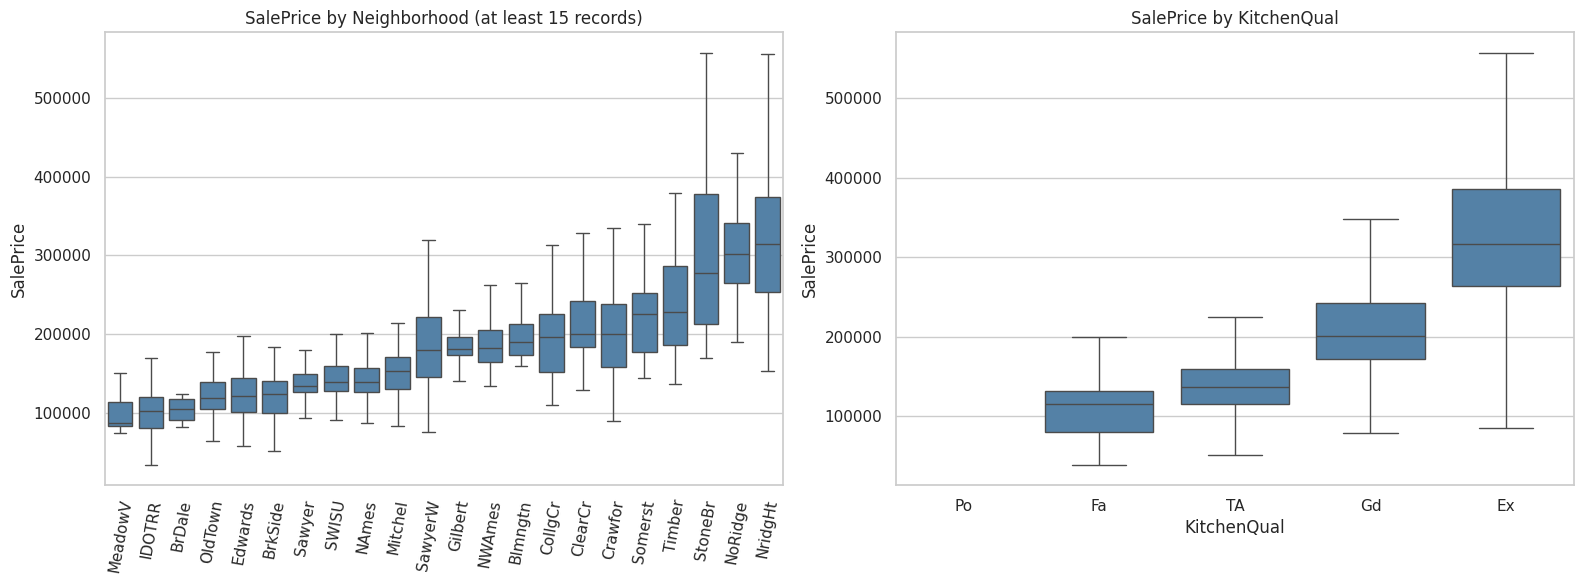

In [10]:
def summarize_category(feature):
    label = train[feature].fillna('__MISSING__').astype(str)
    table = train.assign(_category=label).groupby('_category')[TARGET].agg(
        Count='size', Median='median', Mean='mean'
    )
    return table.sort_values('Median', ascending=False)

for col in ['Neighborhood', 'KitchenQual', 'MSZoning', 'HouseStyle']:
    print(f'\n{col}:')
    display(summarize_category(col).round(2).head(12))

# Exclude very small neighborhoods from this visualization only.
neighborhood_stats = summarize_category('Neighborhood')
valid_neighborhoods = neighborhood_stats.loc[neighborhood_stats['Count'] >= 15].index
plot_data = train.loc[train['Neighborhood'].isin(valid_neighborhoods)].copy()
median_order = plot_data.groupby('Neighborhood')[TARGET].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=plot_data, x='Neighborhood', y='SalePrice', order=median_order, ax=axes[0], showfliers=False, color='steelblue')
axes[0].tick_params(axis='x', rotation=80)
axes[0].set_title('SalePrice by Neighborhood (at least 15 records)')
axes[0].set_xlabel('')

qual_order = ['Po', 'Fa', 'TA', 'Gd', 'Ex']
sns.boxplot(data=train, x='KitchenQual', y='SalePrice', order=qual_order, ax=axes[1], showfliers=False, color='steelblue')
axes[1].set_title('SalePrice by KitchenQual')
axes[1].set_xlabel('KitchenQual')
finish_plot('06_categorical_price_boxplots.png')

## 7. Relationships among numeric predictors (multicollinearity)

High correlations can indicate redundant information, such as `GarageCars` versus `GarageArea`. However, correlated predictors need not be deleted automatically: their incremental value depends on the prediction model and other features.

,Feature A,Feature B,Pearson r,Absolute r
540,GarageCars,GarageArea,0.8825,0.8825
148,YearBuilt,GarageYrBlt,0.8257,0.8257
391,GrLivArea,TotRmsAbvGrd,0.8255,0.8255
295,TotalBsmtSF,1stFlrSF,0.8195,0.8195
343,2ndFlrSF,GrLivArea,0.6875,0.6875
476,BedroomAbvGr,TotRmsAbvGrd,0.6766,0.6766
224,BsmtFinSF1,BsmtFullBath,0.6492,0.6492
177,YearRemodAdd,GarageYrBlt,0.6423,0.6423
387,GrLivArea,FullBath,0.6300,0.6300
350,2ndFlrSF,TotRmsAbvGrd,0.6164,0.6164


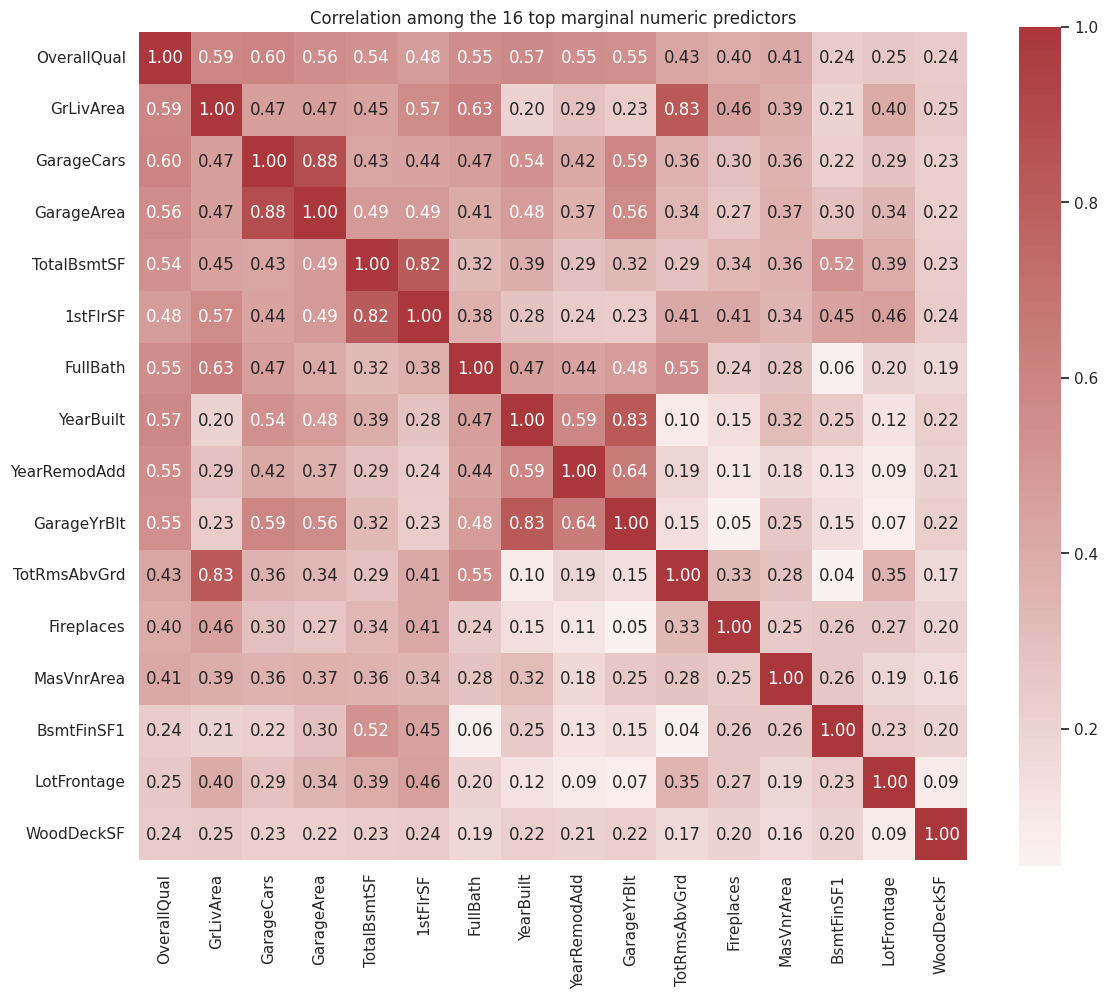

In [11]:
numeric_corr = train[numeric_features].corr(method='pearson')
correlation_pairs = []
for i, col_a in enumerate(numeric_corr.columns):
    for col_b in numeric_corr.columns[i + 1:]:
        value = numeric_corr.loc[col_a, col_b]
        if pd.notna(value):
            correlation_pairs.append({
                'Feature A': col_a,
                'Feature B': col_b,
                'Pearson r': value,
                'Absolute r': abs(value),
            })
correlation_pairs = pd.DataFrame(correlation_pairs).sort_values('Absolute r', ascending=False)
correlation_pairs.to_csv(OUTPUT_DIR / 'numeric_feature_correlations.csv', index=False)

display(correlation_pairs.head(25).round(4))

important_numeric = numeric_associations.head(16)['Feature'].tolist()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(train[important_numeric].corr(), annot=True, fmt='.2f', cmap='vlag', center=0, ax=ax, square=True)
ax.set_title('Correlation among the 16 top marginal numeric predictors')
finish_plot('07_numeric_feature_correlation_matrix.png')

## 8. Relationships among categorical predictors (Cramer's V)

A corrected Cramer's V summarizes association between two categorical variables. It is symmetric and ranges from 0 to 1, but does not imply causation or establish whether both variables should be used in a predictive model. We examine a limited set of representative fields for readability.

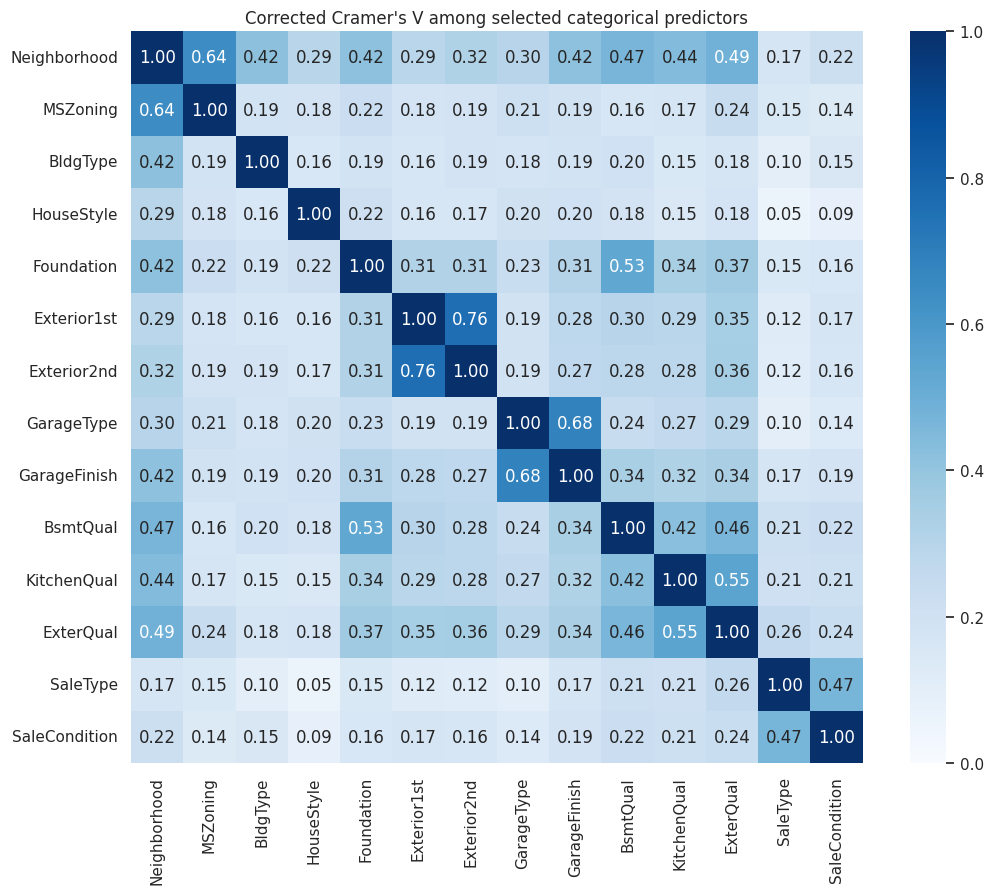

In [12]:
def corrected_cramers_v(a, b):
    a = a.fillna('__MISSING__').astype(str)
    b = b.fillna('__MISSING__').astype(str)
    table = pd.crosstab(a, b)
    if min(table.shape) < 2:
        return 0.0
    chi2, _, _, _ = chi2_contingency(table, correction=False)
    n = table.to_numpy().sum()
    phi2 = chi2 / n
    rows, cols = table.shape
    phi2_corr = max(0.0, phi2 - (cols - 1) * (rows - 1) / (n - 1))
    rows_corr = rows - (rows - 1) ** 2 / (n - 1)
    cols_corr = cols - (cols - 1) ** 2 / (n - 1)
    denominator = min(cols_corr - 1, rows_corr - 1)
    return float(np.sqrt(phi2_corr / denominator)) if denominator > 0 else 0.0


representative_categories = [
    'Neighborhood', 'MSZoning', 'BldgType', 'HouseStyle', 'Foundation',
    'Exterior1st', 'Exterior2nd', 'GarageType', 'GarageFinish',
    'BsmtQual', 'KitchenQual', 'ExterQual', 'SaleType', 'SaleCondition',
]
v_matrix = pd.DataFrame(index=representative_categories, columns=representative_categories, dtype=float)
for col_a in representative_categories:
    for col_b in representative_categories:
        v_matrix.loc[col_a, col_b] = (
            1.0 if col_a == col_b else corrected_cramers_v(train[col_a], train[col_b])
        )

v_matrix.to_csv(OUTPUT_DIR / 'categorical_cramers_v.csv')
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(v_matrix, vmin=0, vmax=1, cmap='Blues', annot=True, fmt='.2f', square=True, ax=ax)
ax.set_title("Corrected Cramer's V among selected categorical predictors")
finish_plot('08_categorical_cramers_v_heatmap.png')

## 9. Investigate nonlinear effects and interactions

Explore whether the relationship between living area and price changes with overall quality. The grouped visualization is descriptive and should not be interpreted as a causal effect. Any subsequently engineered interaction feature needs separate validation.

,QualityGroup,AreaGroup,Count,Median SalePrice
0,Low (1-4),Q1: Small,87,91000.0
1,Low (1-4),Q2,35,109900.0
2,Low (1-4),Q3,15,133000.0
3,Low (1-4),Q4: Large,4,128750.0
4,Medium (5-6),Q1: Small,270,129000.0
5,Medium (5-6),Q2,228,145625.0
6,Medium (5-6),Q3,165,167000.0
7,Medium (5-6),Q4: Large,108,185000.0
8,High (7-8),Q1: Small,8,140200.0
9,High (7-8),Q2,103,185000.0


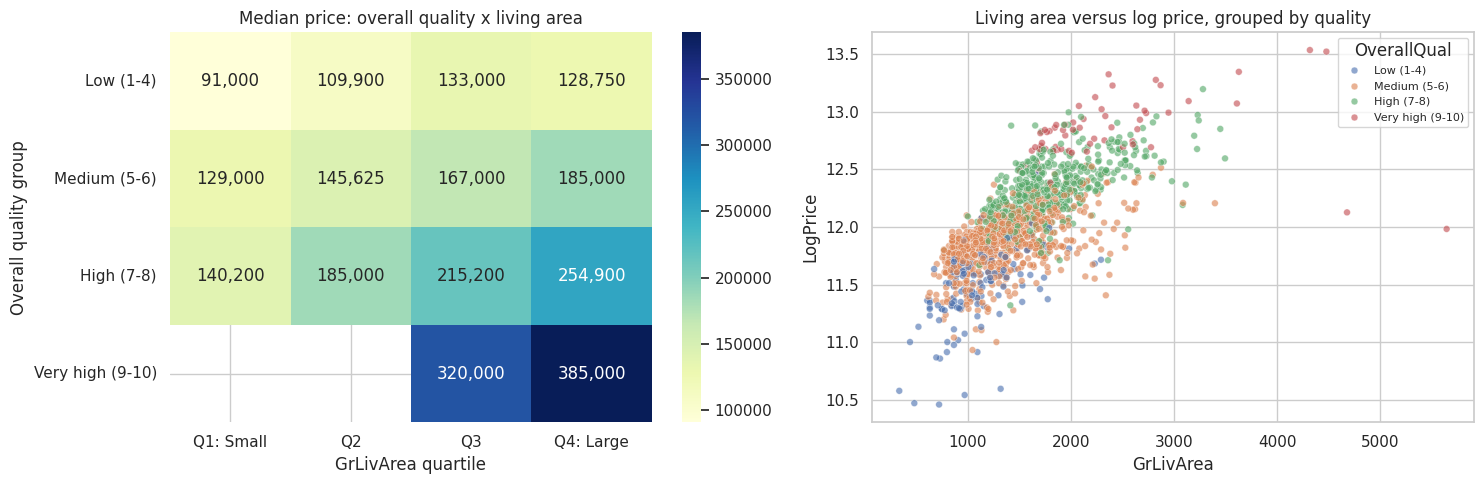

In [13]:
interaction_data = train[['GrLivArea', 'OverallQual', 'SalePrice']].copy()
interaction_data['LogPrice'] = np.log(interaction_data['SalePrice'])
interaction_data['AreaGroup'] = pd.qcut(
    interaction_data['GrLivArea'], q=4, labels=['Q1: Small', 'Q2', 'Q3', 'Q4: Large']
)
interaction_data['QualityGroup'] = pd.cut(
    interaction_data['OverallQual'], bins=[0, 4, 6, 8, 10],
    labels=['Low (1-4)', 'Medium (5-6)', 'High (7-8)', 'Very high (9-10)']
)

interaction_summary = interaction_data.groupby(
    ['QualityGroup', 'AreaGroup'], observed=True
)['SalePrice'].agg(['size', 'median']).reset_index()
interaction_summary.to_csv(OUTPUT_DIR / 'area_quality_interaction_summary.csv', index=False)
display(interaction_summary.rename(columns={'size':'Count', 'median':'Median SalePrice'}))

heatmap_data = interaction_summary.pivot(index='QualityGroup', columns='AreaGroup', values='median')
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(heatmap_data, annot=True, fmt=',.0f', cmap='YlGnBu', ax=axes[0])
axes[0].set_title('Median price: overall quality x living area')
axes[0].set_xlabel('GrLivArea quartile')
axes[0].set_ylabel('Overall quality group')
sns.scatterplot(
    data=interaction_data, x='GrLivArea', y='LogPrice',
    hue='QualityGroup', s=24, alpha=0.62, ax=axes[1]
)
axes[1].set_title('Living area versus log price, grouped by quality')
axes[1].legend(title='OverallQual', fontsize=8, loc='best')
finish_plot('09_area_quality_interaction.png')

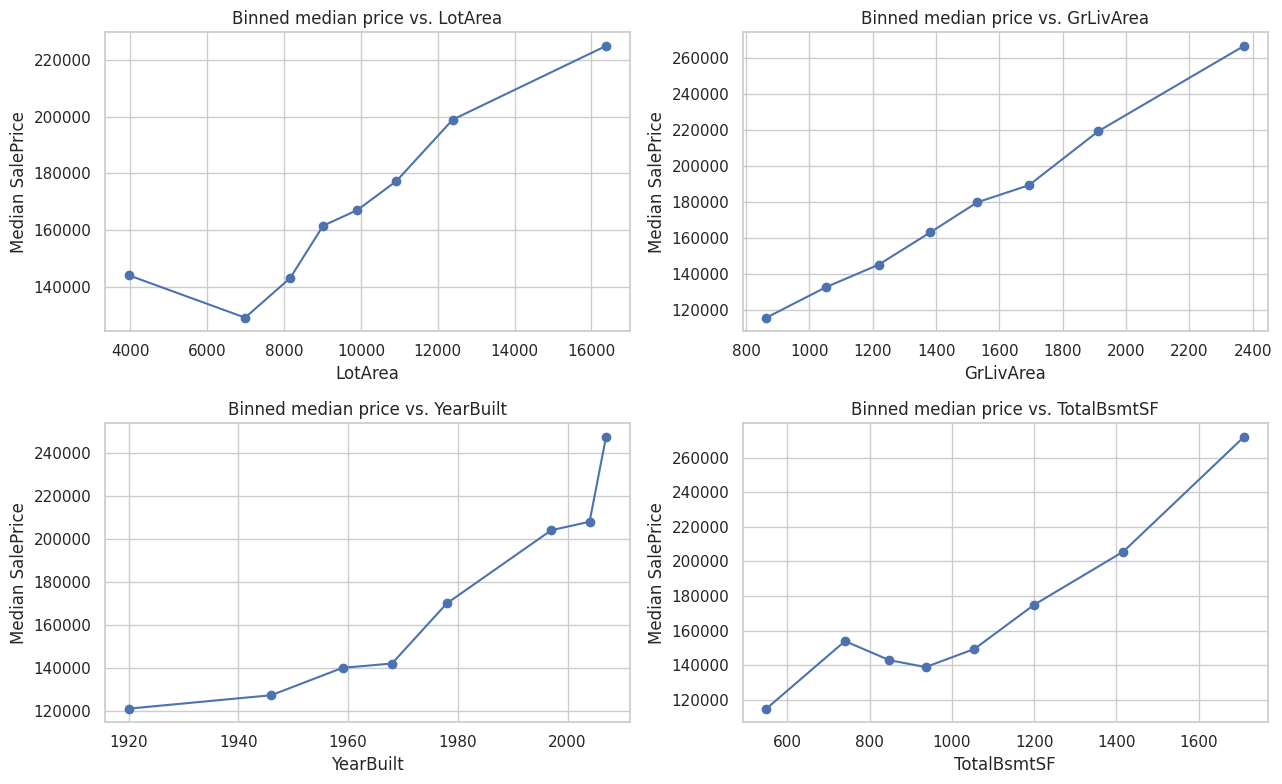

In [14]:
# Quantile-binned medians can help reveal nonlinear marginal trends.
trend_features = ['LotArea', 'GrLivArea', 'YearBuilt', 'TotalBsmtSF']
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, feature in zip(axes.flat, trend_features):
    temp = train[[feature, TARGET]].dropna().copy()
    temp['Bin'] = pd.qcut(temp[feature], q=8, duplicates='drop')
    curve = temp.groupby('Bin', observed=True).agg(
        MedianFeature=(feature, 'median'),
        MedianPrice=(TARGET, 'median'),
        Count=(TARGET, 'size'),
    )
    ax.plot(curve['MedianFeature'], curve['MedianPrice'], marker='o')
    ax.set_title(f'Binned median price vs. {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Median SalePrice')

finish_plot('10_binned_numeric_trends.png')

## 10. Mutual information ranking for all predictors

Mutual information can detect nonlinear statistical dependence. Nominal categories are encoded as integer labels **only for this MI estimator** and marked as discrete; the labels do **not** imply an ordering. Numeric columns receive median imputation for this exploratory calculation. This estimator can be noisy with 1,460 rows, so MI rankings should be compared with other methods rather than treated as a definitive selection.

,Feature,Group,Type,Mutual Information
16,OverallQual,Structure and exterior,Numeric,0.5781
11,Neighborhood,Land and location,Categorical,0.5283
45,GrLivArea,Interior and living space,Numeric,0.4590
18,YearBuilt,Structure and exterior,Numeric,0.3672
61,GarageArea,Garage and parking,Numeric,0.3656
37,TotalBsmtSF,Basement,Numeric,0.3616
60,GarageCars,Garage and parking,Numeric,0.3588
29,BsmtQual,Basement,Categorical,0.3286
26,ExterQual,Structure and exterior,Categorical,0.3269
52,KitchenQual,Interior and living space,Categorical,0.3216


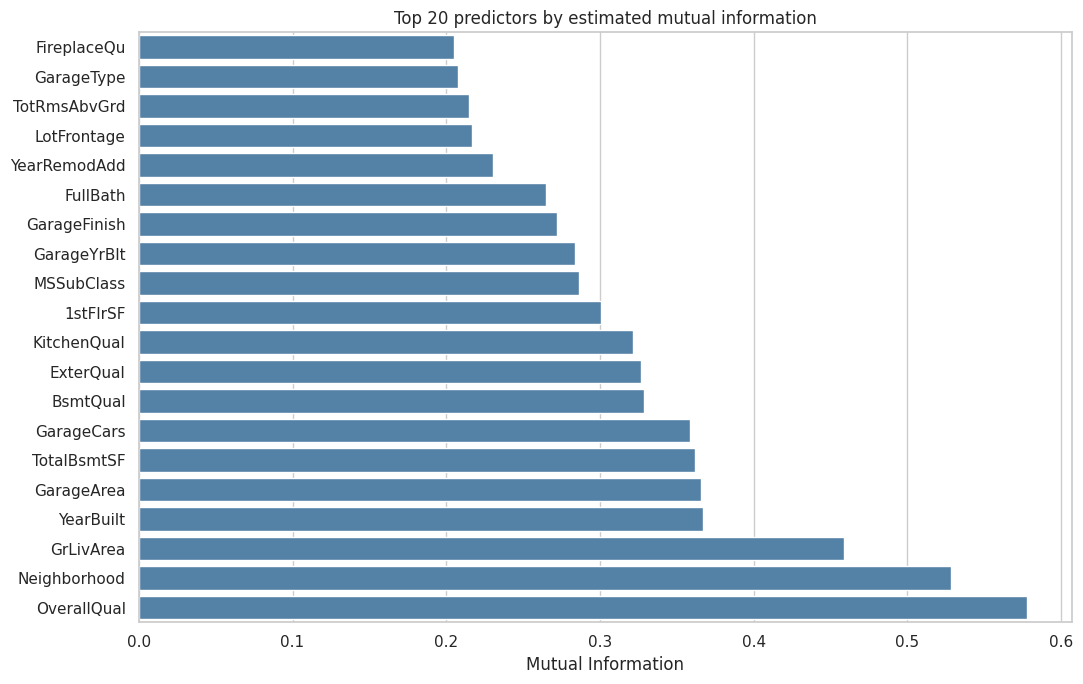

In [15]:
X_mi = pd.DataFrame(index=train.index)
discrete_flags = []

for col in FEATURES:
    if col in categorical_features:
        labels = train[col].fillna('__MISSING__').astype(str)
        codes, _ = pd.factorize(labels, sort=True)
        X_mi[col] = codes.astype(int)
        discrete_flags.append(True)
    else:
        values = pd.to_numeric(train[col], errors='coerce')
        median_value = values.median()
        X_mi[col] = values.fillna(median_value if pd.notna(median_value) else 0.0)
        discrete_flags.append(False)

assert X_mi.notna().sum().sum() == X_mi.size
mi_scores = mutual_info_regression(
    X_mi.to_numpy(dtype=float),
    log_target.to_numpy(),
    discrete_features=np.asarray(discrete_flags, dtype=bool),
    n_neighbors=3,
    random_state=RANDOM_STATE,
)

mi_table = pd.DataFrame({
    'Feature': FEATURES,
    'Group': [feature_to_group[col] for col in FEATURES],
    'Type': ['Categorical' if col in categorical_features else 'Numeric' for col in FEATURES],
    'Mutual Information': mi_scores,
}).sort_values('Mutual Information', ascending=False)

mi_table.to_csv(OUTPUT_DIR / 'mutual_information_scores.csv', index=False)
display(mi_table.head(25).round(4))

fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=mi_table.head(20).sort_values('Mutual Information'), x='Mutual Information', y='Feature', ax=ax, color='steelblue')
ax.set_title('Top 20 predictors by estimated mutual information')
ax.set_ylabel('')
finish_plot('11_mutual_information_rankings.png')

## 11. Compare feature-selection signals

Combine marginal correlations, eta-squared, mutual information, and missingness into a single table. These quantities measure different things and should not be added together without a justified weighting scheme. Missing values in a metric simply mean that the metric was not calculated for that variable type.

In [16]:
feature_report = quality_summary.merge(
    numeric_associations[['Feature', 'Pearson with log price', 'Spearman with log price', 'Abs Pearson', 'Abs Spearman']],
    on='Feature', how='left'
).merge(
    categorical_associations[['Feature', 'Eta squared (log price)']],
    on='Feature', how='left'
).merge(
    mi_table[['Feature', 'Mutual Information']],
    on='Feature', how='left'
)

feature_report['MI rank'] = feature_report['Mutual Information'].rank(ascending=False, method='min').astype(int)
feature_report = feature_report.sort_values('MI rank')
feature_report.to_csv(OUTPUT_DIR / 'feature_screening_summary.csv', index=False)

print('All-feature screening overview (top 25 by MI):')
display(feature_report[[
    'Feature', 'Group', 'Type', 'Train NA %', 'Unique non-NA values',
    'Pearson with log price', 'Spearman with log price',
    'Eta squared (log price)', 'Mutual Information', 'MI rank'
]].head(25).round(3))

print('Top 10 MI features by data-field group:')
display(mi_table.head(10).groupby('Group').agg(Number=('Feature', 'size'), Max_MI=('Mutual Information','max')))

All-feature screening overview (top 25 by MI):


,Feature,Group,Type,Train NA %,Unique non-NA values,Pearson with log price,Spearman with log price,Eta squared (log price),Mutual Information,MI rank
16,OverallQual,Structure and exterior,Numeric,0.000,10,0.817,0.810,NaN,0.578,1
11,Neighborhood,Land and location,Categorical,0.000,25,NaN,NaN,0.571,0.528,2
45,GrLivArea,Interior and living space,Numeric,0.000,861,0.701,0.731,NaN,0.459,3
18,YearBuilt,Structure and exterior,Numeric,0.000,112,0.587,0.653,NaN,0.367,4
61,GarageArea,Garage and parking,Numeric,0.000,441,0.651,0.649,NaN,0.366,5
37,TotalBsmtSF,Basement,Numeric,0.000,721,0.612,0.603,NaN,0.362,6
60,GarageCars,Garage and parking,Numeric,0.000,5,0.681,0.691,NaN,0.359,7
29,BsmtQual,Basement,Categorical,2.534,4,NaN,NaN,0.452,0.329,8
26,ExterQual,Structure and exterior,Categorical,0.000,4,NaN,NaN,0.461,0.327,9
52,KitchenQual,Interior and living space,Categorical,0.000,4,NaN,NaN,0.448,0.322,10


Top 10 MI features by data-field group:


,Number,Max_MI
Group,,
Basement,2,0.361609
Garage and parking,2,0.365620
Interior and living space,2,0.459049
Land and location,1,0.528286
Structure and exterior,3,0.578051


## 12. Train/test consistency and unseen categories

The Kaggle test set contains no price labels. It can still be checked for missing-value differences, categories not observed in the training data, and out-of-range values. Do not use the hidden test labels (or repeated leaderboard attempts) for feature selection.

In [17]:
print('Largest train/test differences in NA marker rate:')
quality_summary['NA rate gap (test - train), pp'] = (
    quality_summary['Test NA %'] - quality_summary['Train NA %']
)
display(
    quality_summary.iloc[quality_summary['NA rate gap (test - train), pp'].abs().argsort()[::-1]][[
        'Feature', 'Train NA %', 'Test NA %', 'NA rate gap (test - train), pp'
    ]].head(15).round(3)
)

unseen_rows = []
for col in categorical_features:
    train_levels = set(train[col].fillna('__MISSING__').astype(str).unique())
    test_levels = set(test[col].fillna('__MISSING__').astype(str).unique())
    unseen = sorted(test_levels - train_levels)
    if unseen:
        unseen_rows.append({
            'Feature': col,
            'Unseen categories in test': ', '.join(unseen),
            'Count of unseen categories': len(unseen),
        })

unseen_table = pd.DataFrame(
    unseen_rows,
    columns=['Feature', 'Unseen categories in test', 'Count of unseen categories']
)
unseen_table.to_csv(OUTPUT_DIR / 'train_test_unseen_categories.csv', index=False)
print('Categorical predictors with unseen levels in test:', len(unseen_table))
display(unseen_table)

Largest train/test differences in NA marker rate:


,Feature,Train NA %,Test NA %,"NA rate gap (test - train), pp"
56,FireplaceQu,47.260,50.034,2.774
2,LotFrontage,17.740,15.559,-2.181
5,Alley,93.767,92.666,-1.101
72,Fence,80.753,80.123,-0.630
30,BsmtCond,2.534,3.084,0.550
24,MasVnrType,0.548,1.097,0.549
29,BsmtQual,2.534,3.016,0.482
25,MasVnrArea,0.548,1.028,0.480
31,BsmtExposure,2.603,3.016,0.413
32,BsmtFinType1,2.534,2.879,0.344


Categorical predictors with unseen levels in test: 8


,Feature,Unseen categories in test,Count of unseen categories
0,MSSubClass,150,1
1,MSZoning,__MISSING__,1
2,Utilities,__MISSING__,1
3,Exterior1st,__MISSING__,1
4,Exterior2nd,__MISSING__,1
5,KitchenQual,__MISSING__,1
6,Functional,__MISSING__,1
7,SaleType,__MISSING__,1


## 13. Suspicious observations to investigate (do not delete automatically)

The following are *review flags*, not confirmed errors. A very large home with a low sale price may be legitimate, and a recorded year after the sale year may reflect a special transaction or data issue.

In [18]:
anomaly_rows = []

for dataset_name, frame in [('train', train), ('test', test)]:
    checks = {
        'GarageYrBlt after sale year + 1': frame['GarageYrBlt'] > frame['YrSold'] + 1,
        'YearBuilt after sale year': frame['YearBuilt'] > frame['YrSold'],
        'Basement marked NA despite positive area': frame['BsmtQual'].isna() & (frame['TotalBsmtSF'].fillna(0) > 0),
        'Masonry type None despite positive area': (frame['MasVnrType'] == 'None') & (frame['MasVnrArea'].fillna(0) > 0),
    }
    if dataset_name == 'train':
        checks['Very large above-ground living area (> 4,000)'] = frame['GrLivArea'] > 4000
    for label, mask in checks.items():
        for _, record in frame.loc[mask].iterrows():
            anomaly_rows.append({
                'Dataset': dataset_name,
                'Id': int(record['Id']),
                'Flag': label,
                'GrLivArea': record['GrLivArea'],
                'YearBuilt': record['YearBuilt'],
                'YrSold': record['YrSold'],
                'GarageYrBlt': record['GarageYrBlt'],
                'SalePrice': record.get('SalePrice', np.nan),
            })

anomaly_table = pd.DataFrame(
    anomaly_rows,
    columns=['Dataset','Id','Flag','GrLivArea','YearBuilt','YrSold','GarageYrBlt','SalePrice']
)
anomaly_table.to_csv(OUTPUT_DIR / 'anomaly_review_candidates.csv', index=False)
print('Number of flagged records (one record may have multiple flags):', len(anomaly_table))
display(anomaly_table.head(35))

Number of flagged records (one record may have multiple flags): 15


,Dataset,Id,Flag,GrLivArea,YearBuilt,YrSold,GarageYrBlt,SalePrice
0,train,625,Masonry type None despite positive area,1790,1972,2006,1972.0,165150.0
1,train,774,Masonry type None despite positive area,912,1958,2007,1958.0,114500.0
2,train,1231,Masonry type None despite positive area,2620,1977,2007,1977.0,190000.0
3,train,1301,Masonry type None despite positive area,1983,1999,2009,1999.0,225000.0
4,train,1335,Masonry type None despite positive area,1365,1970,2009,1970.0,125000.0
5,train,524,"Very large above-ground living area (> 4,000)",4676,2007,2007,2007.0,184750.0
6,train,692,"Very large above-ground living area (> 4,000)",4316,1994,2007,1994.0,755000.0
7,train,1183,"Very large above-ground living area (> 4,000)",4476,1996,2007,1996.0,745000.0
8,train,1299,"Very large above-ground living area (> 4,000)",5642,2008,2008,2008.0,160000.0
9,test,2593,GarageYrBlt after sale year + 1,1564,2006,2007,2207.0,NaN


## 14. EDA recap and the next modeling experiment

### Suggested first modeling comparisons

- **Baseline:** All 79 original predictors, consistent missing-value processing and encoding, and a Ridge or tree-based regression model.
- **Filter-based screening:** Compare the full feature set with selected top-k variables from Pearson/Spearman (numeric only) and mixed-feature MI.
- **Embedded screening:** Lasso or tree-based importance fitted **within training folds**.
- **Feature creation:** Evaluate additions such as `HouseAge`, `TotalSF`, `TotalBath`, and `QualityArea`, one group at a time.
- **Model comparison:** Hold features fixed when comparing Ridge, Random Forest, and XGBoost; hold model settings fixed when evaluating feature sets.

### Validation rule

Use the same cross-validation folds and log-price RMSE to compare alternatives. If a selection method uses `SalePrice`, it **must** be refitted on the training portion of each fold (e.g., inside a scikit-learn pipeline or nested CV). The rankings in this notebook are for exploration and hypothesis generation only. Do not rely on leaderboard scores to perform repeated selection.

### Saved output files

All CSV summary tables and PNG plots are stored in `eda_outputs/`. The most useful file for the later feature-selection stage is **`feature_screening_summary.csv`**.

In [19]:
files_created = sorted(path.name for path in OUTPUT_DIR.iterdir() if path.is_file())
print('EDA output files:')
for name in files_created:
    print('-', name)

print('\nFinal checks:')
print('Predictor count:', len(FEATURES))
print('All predictors represented in screening report:', set(feature_report['Feature']) == set(FEATURES))
print('All predictors represented in MI table:', set(mi_table['Feature']) == set(FEATURES))
print('Train/test predictor columns match:', set(train[FEATURES].columns) == set(test.drop(columns='Id').columns))

EDA output files:
- 01_missing_markers_train.png
- 02_target_distribution.png
- 03_numeric_target_correlations.png
- 04_top_numeric_scatterplots.png
- 05_categorical_target_eta_squared.png
- 06_categorical_price_boxplots.png
- 07_numeric_feature_correlation_matrix.png
- 08_categorical_cramers_v_heatmap.png
- 09_area_quality_interaction.png
- 10_binned_numeric_trends.png
- 11_mutual_information_rankings.png
- anomaly_review_candidates.csv
- area_quality_interaction_summary.csv
- categorical_cramers_v.csv
- categorical_target_associations.csv
- feature_dictionary_and_quality.csv
- feature_screening_summary.csv
- mutual_information_scores.csv
- numeric_feature_correlations.csv
- numeric_target_associations.csv
- train_test_unseen_categories.csv

Final checks:
Predictor count: 79
All predictors represented in screening report: True
All predictors represented in MI table: True
Train/test predictor columns match: True
